In [1]:
import pandas as pd 
import tifffile as tf
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from src import data

In [3]:
alldata = data.load_all_excels(inclusions=['NeuroD'],exclusions=None)
datadf = data.generate_dataset(alldata,copy_type = 'local_no_copy',local_data_folder = 'data_sgn')

100%|██████████| 217/217 [00:00<00:00, 18531.28it/s]

Avg file does not exist locally: data_sgn/2023_03_31_NeuroD-GCaMP6f_P4_in vivo_1_Avg.tif
Avg file does not exist locally: data_sgn/2023_04_04_NeuroD-GCaMP6f_P8_in vivo_1_Avg.tif
Avg file does not exist locally: data_sgn/2023_06_09_NeuroD-GCaMP6f_P8_in vivo_1_Avg.tif
Avg file does not exist locally: data_sgn/2025_04_28_NeuroD-GCaMP6f_P7_in vivo_injectable anaesthetic_3_Avg.tif
Avg file does not exist locally: data_sgn/2025_04_28_NeuroD-GCaMP6f_P7_in vivo_injectable anaesthetic_3_001_Avg.tif
Avg file does not exist locally: data_sgn/2025_04_28_NeuroD-GCaMP6f_P7_in vivo_injectable anaesthetic_3_002_Avg.tif
Avg file does not exist locally: data_sgn/2023_02_27_NeuroD-Cre-GCaMP6f_P6_in vivo_9_Avg.tif
Avg file does not exist locally: data_sgn/2023_02_27_NeuroD-Cre-GCaMP6f_P6_in vivo_10_Avg.tif
Avg file does not exist locally: data_sgn/2023_03_03_NeuroD-Cre-GCaMP6f_P4_in vivo_5_Avg.tif
Avg file does not exist locally: data_sgn/2023_03_03_NeuroD-Cre-GCaMP6f_P4_in vivo_6_Avg.tif
Avg file does no

np.int64(277485)

In [38]:
from scipy import ndimage as ndi
from skimage.feature import peak_local_max
from skimage.measure import regionprops

def return_center_points(mask):
    rprops = regionprops(mask)

    center_points = []
    for i in range(len(rprops)):
        label = rprops[i].label

        mask_i = mask.copy()
        mask_i[mask_i != label] = 0

        distance_map = ndi.distance_transform_edt(mask_i)
        distance_y, distance_x = np.unravel_index(np.argmax(distance_map), distance_map.shape)   
        center_points.append((distance_x, distance_y))
    return center_points

def center_heatmap(mask, gaussian_sigma=2):
    shape = mask.shape
    center_points = return_center_points(mask)
    heatmap = np.zeros(shape)
    for point in center_points:
        heatmap[point[1], point[0]] = 1

    heatmap = ndi.gaussian_filter(heatmap, sigma=gaussian_sigma)
    return heatmap

Text(0.5, 1.0, 'heatmap over raw')

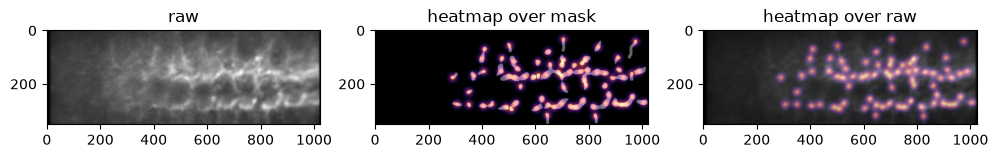

In [43]:
mask  = tf.imread(datadf.loc[4,'Maskfile'])
img = tf.imread(datadf.loc[4,'Avgfile'])
from scipy import ndimage as ndi
from skimage.feature import peak_local_max



hm = center_heatmap(mask, gaussian_sigma=10)
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("raw")

plt.subplot(1, 3, 2)
plt.imshow(mask > 0, cmap="gray")
plt.imshow(hm, cmap="magma", alpha=0.6)
plt.title("heatmap over mask")

plt.subplot(1, 3, 3)
plt.imshow(img, cmap="gray")
plt.imshow(hm, cmap="magma", alpha=0.5)
plt.title("heatmap over raw")




In [48]:
from src import model,transforms

mm = model.UNet(2,1,1,[16, 32, 64, 128, 256], [2, 2, 2, 2])